# XiangqiRL — PPO training on Kaggle

Trains the policy-value network with PPO against the random and heuristic baselines (Phase 4).

**Before running**
1. Notebook settings: **Accelerator = GPU T4** (CPU works too, only slower) and **Internet = On** (needed to `git clone` and `pip install gymnasium`).
2. The project is cloned from GitHub in section 1 (`REPO_URL`). A public repo is cloned anonymously. For a **private** repo, add a Kaggle *Secret* named `GITHUB_TOKEN` (Add-ons → Secrets) with a personal access token that has `repo` read access.
3. *(Optional, to continue an earlier run)* upload `latest.pt` from a previous session as a dataset and set `RESUME_FROM` below.

Passing tests shows the code behaves as specified; it does **not** by itself show that the agent plays well. Judge that from the evaluation section at the end.

In [1]:
import os, shutil, subprocess, sys, glob, time
import torch
print("python", sys.version.split()[0], "| torch", torch.__version__)
print("CUDA available:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

python 3.13.15 | torch 2.11.0+cu128
CUDA available: True Tesla T4


## 1. Clone and install the project

In [2]:
REPO_URL = "https://github.com/TamasTran/xiangqi-rl.git"
BRANCH   = "main"          # branch, tag or commit to use
PROJECT  = "/kaggle/working/xiangqi-rl"

import socket
try:
    socket.create_connection(("github.com", 443), timeout=10).close()
except OSError as exc:
    raise RuntimeError(
        "Cannot reach github.com -> turn Internet ON in the notebook settings "
        "(right sidebar > Session options > Internet), then re-run."
    ) from exc

def try_clone(url: str) -> subprocess.CompletedProcess:
    if os.path.exists(PROJECT):
        shutil.rmtree(PROJECT)
    return subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", BRANCH, url, PROJECT],
        capture_output=True, text=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )

# 1) anonymous clone (works for a public repo); a stale token must not break this.
r = try_clone(REPO_URL)
if r.returncode != 0:
    # 2) private repo: use the Kaggle Secret GITHUB_TOKEN if one exists.
    print("anonymous clone failed:", r.stderr.strip()[-400:])
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception as exc:
        raise RuntimeError(
            "Clone failed and no GITHUB_TOKEN secret is available. For a private repo add a "
            "Kaggle Secret named GITHUB_TOKEN (Add-ons > Secrets) and attach it to this notebook."
        ) from exc
    authed = REPO_URL.replace("https://", f"https://x-access-token:{token}@")
    r = try_clone(authed)
    if r.returncode != 0:
        raise RuntimeError("authenticated clone failed:\n" + r.stderr.replace(token, "***")[-600:])
    subprocess.run(["git", "-C", PROJECT, "remote", "set-url", "origin", REPO_URL], check=True)  # drop token

os.chdir(PROJECT)
print("commit:", subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout.strip())

commit: 5ab81bb PPO: optional potential-based material reward shaping


In [3]:
# --no-deps keeps Kaggle's preinstalled (CUDA) torch; only the small extras are installed.
!pip install -q -e . --no-deps
!pip install -q gymnasium pyyaml

# The kernel is already running, so the editable install is not visible to *this* process
# until its path is refreshed (new `!python ...` processes see it without this).
import importlib
sys.path.insert(0, os.path.join(PROJECT, "src"))
importlib.invalidate_caches()

import xiangqi_rl, gymnasium, yaml
print("xiangqi_rl", xiangqi_rl.__version__, "| gymnasium", gymnasium.__version__)

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for xiangqi-rl (pyproject.toml) ... done
xiangqi_rl 0.1.0 | gymnasium 1.2.0


## 2. Tests and smoke test (about a minute)

In [4]:
!python -m pip install -q pytest
!python -m pytest -q -x tests

........................................................................ [ 18%]
........................................................................ [ 37%]
........................................................................ [ 55%]
........................................................................ [ 74%]
........................................................................ [ 93%]
..........................                                               [100%]
=============================== warnings summary ===============================
tests/nn/test_checkpoint.py::test_untrusted_pickle_is_refused
  /usr/local/lib/python3.13/dist-packages/torch/_weights_only_unpickler.py:590: UserWarning: Detected pickle protocol 4 in the checkpoint, which was not the default pickle protocol used by `torch.load` (2). The weights_only Unpickler might not support all instructions implemented by this protocol, please file an issue for adding support if you encounter this.
    return Unpi

In [5]:
!python scripts/train_ppo.py --config configs/ppo_baseline.yaml --smoke-test

device=cuda output_dir=/tmp/xiangqi_ppo_smoke_ssu36p9j parameters=2,937,189
[eval @ iter 0] score=0.500 (random: W0/D2/L0, heuristic: W0/D2/L0)
iter    1 | decisions      64 | R +0.00 (shaped +0.04) len 20 W0/D3/L0 | pi -0.0198 v 0.0071 H 3.324 kl 0.0006 clip 0.00 ev -0.00 | env 0.3s inf 0.2s upd 0.4s
[eval @ iter 1] score=0.500 (random: W0/D2/L0, heuristic: W0/D2/L0)
iter    2 | decisions     128 | R -0.25 (shaped -0.18) len 16 W0/D3/L1 | pi -0.0045 v 0.0579 H 2.618 kl 0.0000 clip 0.00 ev 0.01 | env 0.3s inf 0.1s upd 0.0s
[eval @ iter 2] score=0.500 (random: W0/D2/L0, heuristic: W0/D2/L0)
finished at iteration 2; checkpoints in /tmp/xiangqi_ppo_smoke_ssu36p9j
smoke: checkpoint reload matches; 30 sampled actions were legal
iter    3 | decisions     192 | R +0.00 (shaped +0.01) len 20 W0/D3/L0 | pi -0.0030 v 0.0077 H 3.471 kl 0.0000 clip 0.00 ev 0.03 | env 0.2s inf 0.1s upd 0.2s
[eval @ iter 3] score=0.500 (random: W0/D2/L0, heuristic: W0/D2/L0)
smoke: resumed from iteration 2 and compl

## 3. Training configuration

Edit these values. Everything else comes from `configs/ppo_baseline.yaml`.
One iteration of the baseline config (2048 decisions) took about 25 s on a CPU-only
development machine; the game simulation is CPU-bound, so a T4 mainly speeds up the update.

In [6]:
RUN_NAME     = "shaping1"                    # change for every NEW run (logs/checkpoints are per run)
OUTPUT_DIR   = f"/kaggle/working/runs/{RUN_NAME}"
ITERATIONS   = 1000                       # total rollout+update cycles
ROLLOUT_STEPS, MINIBATCH = 2048, 256
LEARNING_RATE = 1e-4
TARGET_KL     = 0.02                     # early-stop PPO epochs when approx_kl exceeds this
MATERIAL_SHAPING = 0.5                   # potential-based material shaping; 0 = sparse reward only
EVAL_INTERVAL, EVAL_GAMES = 10, 20       # evaluate every N iterations, games per opponent (even)
SEED = 0
RESUME_FROM = None                       # continue a run: f"{OUTPUT_DIR}/latest.pt" or "/kaggle/input/<dataset>/latest.pt"

overrides = {
    "total_iterations": ITERATIONS, "rollout_steps": ROLLOUT_STEPS, "minibatch_size": MINIBATCH,
    "learning_rate": LEARNING_RATE, "target_kl": TARGET_KL,
    "material_shaping_coef": MATERIAL_SHAPING, "eval_interval": EVAL_INTERVAL, "eval_games": EVAL_GAMES,
    "seed": SEED, "output_dir": OUTPUT_DIR,
}
SET_ARGS = " ".join(f"--set {k}={v}" for k, v in overrides.items())
RESUME_ARGS = f"--resume {RESUME_FROM}" if RESUME_FROM else ""
print(SET_ARGS, RESUME_ARGS)

--set total_iterations=1000 --set rollout_steps=2048 --set minibatch_size=256 --set learning_rate=0.0001 --set target_kl=0.02 --set material_shaping_coef=0.5 --set eval_interval=10 --set eval_games=20 --set seed=0 --set output_dir=/kaggle/working/runs/shaping1 


## 4. Train

A new run needs a new `RUN_NAME` (the trainer refuses to mix two runs in one directory). To continue a run, keep `RUN_NAME` and set `RESUME_FROM = f"{OUTPUT_DIR}/latest.pt"`; raise `ITERATIONS` to train longer.

In [7]:
!python scripts/train_ppo.py --config configs/ppo_baseline.yaml --device auto {SET_ARGS} {RESUME_ARGS}

device=cuda output_dir=/kaggle/working/runs/shaping1 parameters=6,193,221
[eval @ iter 0] score=0.237 (random: W0/D19/L1, heuristic: W0/D0/L20)
iter    1 | decisions    2048 | R -0.64 (shaped -0.57) len 57 W0/D13/L23 | pi -0.0661 v 0.0157 H 3.140 kl 0.0148 clip 0.27 ev -0.01 | env 5.0s inf 4.5s upd 1.0s
iter    2 | decisions    4096 | R -0.52 (shaped -0.47) len 64 W0/D15/L16 | pi -0.0693 v 0.0106 H 3.271 kl 0.0142 clip 0.25 ev 0.07 | env 4.4s inf 4.5s upd 0.9s
iter    3 | decisions    6144 | R -0.47 (shaped -0.42) len 65 W0/D17/L15 | pi -0.0680 v 0.0080 H 3.305 kl 0.0146 clip 0.25 ev 0.27 | env 4.1s inf 4.4s upd 0.9s
iter    4 | decisions    8192 | R -0.24 (shaped -0.22) len 82 W2/D15/L8 | pi -0.0469 v 0.0131 H 3.357 kl 0.0102 clip 0.15 ev 0.13 | env 3.5s inf 4.4s upd 0.7s
iter    5 | decisions   10240 | R -0.54 (shaped -0.49) len 60 W1/D14/L20 | pi -0.0520 v 0.0136 H 3.148 kl 0.0101 clip 0.17 ev 0.31 | env 4.6s inf 4.5s upd 0.7s
iter    6 | decisions   12288 | R -0.58 (shaped -0.51) l

## 5. Training curves

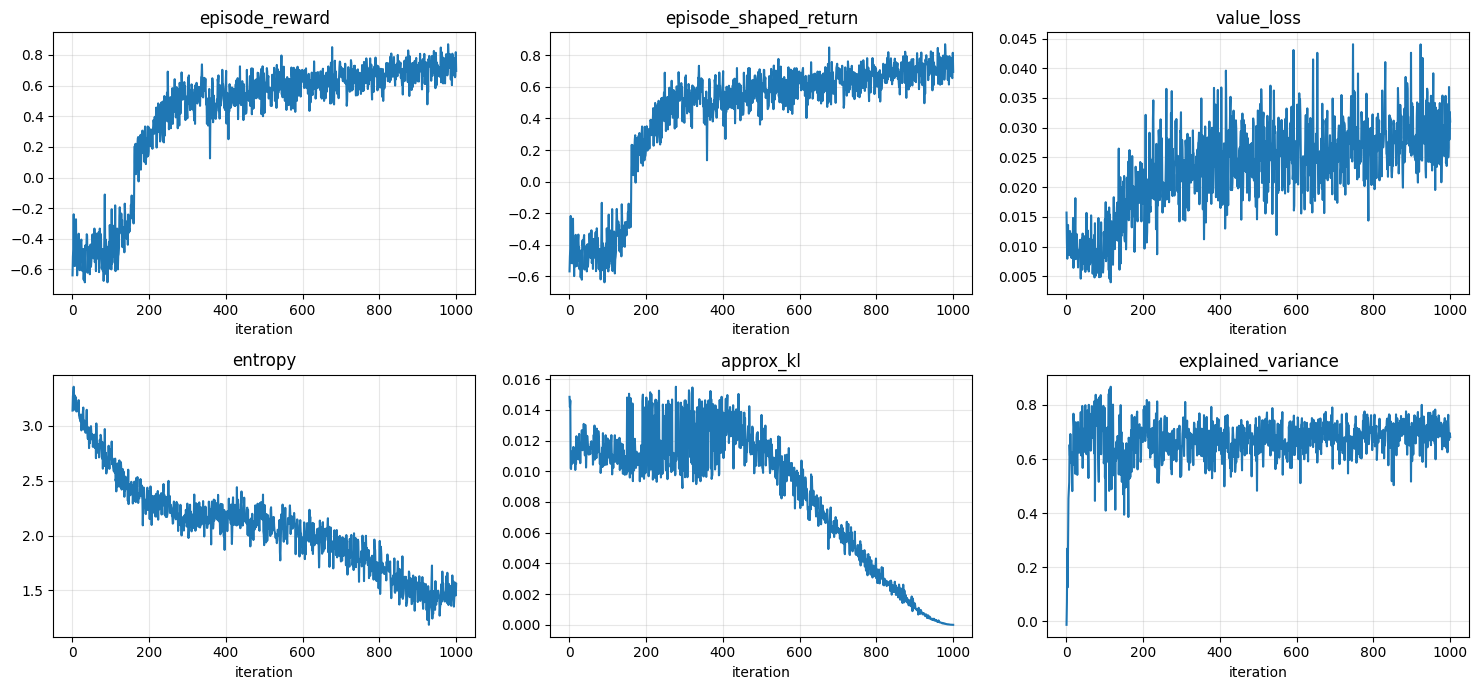

,iteration,decisions,episode_reward,wins,draws,losses,env_seconds,inference_seconds,update_seconds
995,996,2039808,0.689189,57.0,11.0,6.0,3.985414,4.453945,0.922870
996,997,2041856,0.654321,64.0,6.0,11.0,4.444025,4.475258,0.923131
997,998,2043904,0.661972,54.0,10.0,7.0,3.905002,4.437600,0.910600
998,999,2045952,0.818182,87.0,6.0,6.0,4.261696,4.414215,0.911237
999,1000,2048000,0.695652,55.0,7.0,7.0,4.170833,4.444807,0.918026


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

log = pd.read_csv(f"{OUTPUT_DIR}/train_log.csv")
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, ["episode_reward", "episode_shaped_return", "value_loss",
                               "entropy", "approx_kl", "explained_variance"]):
    ax.plot(log["iteration"], log[col]); ax.set_title(col); ax.set_xlabel("iteration"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
log[["iteration", "decisions", "episode_reward", "wins", "draws", "losses",
     "env_seconds", "inference_seconds", "update_seconds"]].tail()

In [9]:
ev = pd.read_csv(f"{OUTPUT_DIR}/eval_log.csv")
ev[["iteration", "opponent", "games", "wins", "draws", "losses", "win_rate", "score",
    "average_plies", "invalid_actions"]]

,iteration,opponent,games,wins,draws,losses,win_rate,score,average_plies,invalid_actions
0,0,random,20,0,19,1,0.00,0.475,199.30,0
1,0,heuristic,20,0,0,20,0.00,0.000,61.50,0
2,10,random,20,0,17,3,0.00,0.425,184.60,0
3,10,heuristic,20,0,0,20,0.00,0.000,59.80,0
4,20,random,20,2,16,2,0.10,0.500,191.40,0
...,...,...,...,...,...,...,...,...,...,...
197,980,heuristic,20,18,0,2,0.90,0.900,18.10,0
198,990,random,20,13,7,0,0.65,0.825,87.60,0
199,990,heuristic,20,18,0,2,0.90,0.900,18.10,0
200,1000,random,20,14,5,1,0.70,0.825,82.85,0


## 6. Final evaluation (separate games, many of them)

20 games per opponent is noisy. Use at least a few hundred before drawing conclusions,
and compare checkpoints with the same seed.

In [10]:
!python scripts/evaluate_ppo.py --checkpoint {OUTPUT_DIR}/best.pt --games 200 --seed 12345 --device auto

checkpoint: /kaggle/working/runs/shaping1/best.pt  device: cuda  seed: 12345  greedy: True

vs random: games=200 W154 D42 L4 truncated=0 win_rate=0.770 draw_rate=0.210 avg_plies=66.7 illegal_actions=0
  as red  : games=100 W64 D32 L4
  as black: games=100 W90 D10 L0

vs heuristic: games=200 W167 D2 L31 truncated=0 win_rate=0.835 draw_rate=0.010 avg_plies=23.5 illegal_actions=0
  as red  : games=100 W67 D2 L31
  as black: games=100 W100 D0 L0

Note: with few games these numbers are noisy; compare checkpoints with the same seed.


## 7. Package the results

Download `ppo_run.zip` from the *Output* tab (or save a notebook version) and upload `latest.pt` as a dataset to resume later.

In [11]:
shutil.make_archive("/kaggle/working/ppo_run", "zip", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

['train_log.csv', 'latest.pt', 'eval_log.csv', 'best.pt']
